* データマイニング特別演習 第３回 (DM03) データの収集とデータの構造
  * 静的Webページからの情報収集
  * 動的Webページからの情報収集
    * pythonのライブラリ(selenium)を使ったデータ収集

In [1]:
# Windows の場合：
# ライブラリを pip コマンドを使ってインストール
# pip install selenium
# pip install chromedriver-binary==140.*  # 140 は インストールされている chrome のバージョン

In [5]:
# Google Colab の場合：
# 以下のコメントアウトを外して実行

%%shell
# Seleniumをインストール。
pip install google-colab-selenium
# 日本語フォントをインストール
apt-get -y install fonts-ipafont-gothic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 14.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [google-colab-selenium]
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-ipafont-gothic is already the newest version (00303-21ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [6]:
# ライブラリをインポート
import re
import time
# from selenium import webdriver # Windows の場合はコメントアウトを外す
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.support.select import Select
# import chromedriver_binary # Google colab の場合はコメントアウトする
import google_colab_selenium as webdriver
import matplotlib.pyplot as plt

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

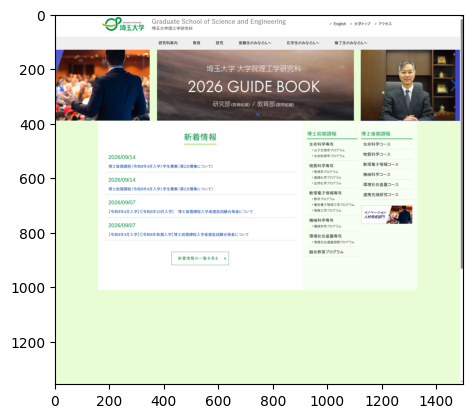

In [7]:
# 動作確認(1) 埼玉大学大学院理工学研究科HPのスクリーンショットを取得
image_file = 'dm03_selenium_screenshot_1.png'
# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless')
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)
driver.set_window_size(1500,1500)
driver.get('https://www.saitama-u.ac.jp/rikogaku/')
time.sleep(5) # 5秒スリープ

# ブラウザのスクリーンショットを保存
driver.save_screenshot(image_file)

# selenium のドライバを修了
driver.quit()

# 画像を読込み変数に格納し、表示
image = plt.imread(image_file)
plt.imshow(image)

<IPython.core.display.Javascript object>

検索結果 1件目 埼玉大学理工学研究科


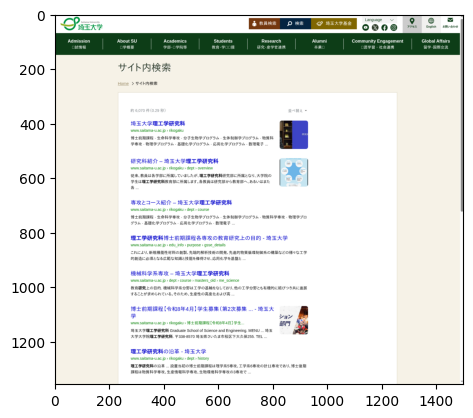

In [8]:
## 動作確認 埼玉大学HPの「検索」で「理工学研究科を」を検索し、検索結果の1件目をクリックして表示
image_file = 'dm03_selenium_screenshot_2.png'
# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless')
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)
driver.set_window_size(1500,1500)
driver.get('https://www.saitama-u.ac.jp/index.html')
time.sleep(1) # 1秒スリープ
# 「検索」をクリック
search_button = driver.find_element(By.CSS_SELECTOR, "#search-box") # #search-box
search_button.click()
time.sleep(1) # 1秒スリープ
# 「理工学研究科」を検索
search = driver.find_element(By.CSS_SELECTOR, "#cse-search-box > input[type=text]:nth-child(4)")
search.send_keys('理工学研究科') # 検索ワードを送信する
time.sleep(1) # 1秒スリープ
search.submit()                 # 検索を実行
time.sleep(1) # 1秒スリープ
#  検索結果 1件目のテキストを表示 (広告除く)
element = driver.find_element(By.CSS_SELECTOR, "#___gcse_0 > div > div > div > div.gsc-wrapper "
                                              + "> div.gsc-resultsbox-visible > div > div "
                                              + "> div.gsc-expansionArea > div:nth-child(1) "
                                              + "> div.gs-webResult.gs-result > div.gsc-thumbnail-inside > div > a")
print('検索結果 1件目', element.text)

# ブラウザのスクリーンショットを保存
driver.save_screenshot(image_file)
# selenium のドライバを修了
driver.quit()

# 画像を読込み変数に格納し、表示
image = plt.imread(image_file)
plt.imshow(image)

<IPython.core.display.Javascript object>

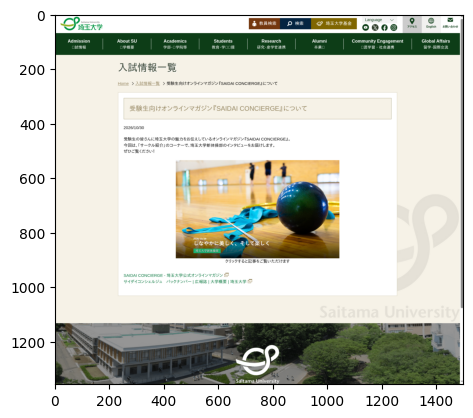

In [10]:
## 動作確認(1) 埼玉大学HPの新着情報の1件目をクリックして表示
image_file = 'dm03_selenium_screenshot_2-1.png'
# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless')
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)

# 埼玉大学HPの新着情報の1件目をクリック
driver.set_window_size(1500,1500)
driver.get('https://www.saitama-u.ac.jp/index.html')
time.sleep(1) # 1秒スリープ
topic = driver.find_element(By.CSS_SELECTOR, "#tab-panel1 > article:nth-child(1) > a")
driver.execute_script("arguments[0].scrollIntoView();", topic) # topic までスクロール
time.sleep(1) # 1秒スリープ
topic.click()
time.sleep(1) # 1秒スリープ

# ブラウザのスクリーンショットを保存
driver.save_screenshot(image_file)
# selenium のドライバを修了
driver.quit()

# 画像を読込み変数に格納し、表示
image = plt.imread(image_file)
plt.imshow(image)

In [12]:
# ライブラリをインポート
import requests
from bs4 import BeautifulSoup

# URLで指定したWebページを取得
url = 'https://www.saitama-u.ac.jp/'
res = requests.get(url)

# BeautifulSoup を使ってHTMLを解析
soup = BeautifulSoup(res.text, "html.parser")

# 所定の箇所を selector で指定して情報を取得
elems = soup.select('#tab-panel1 > article:nth-child(1) > a')
print(elems[0].text)  # テキスト部分を表示
print(elems[0].attrs)   # リンク先等の情報を表示





[2026.10.30]入試情報
 受験生向けオンラインマガジン『SAIDAI CONCIERGE』について 

{'href': '/exam_archives/202610301200.html'}


<IPython.core.display.Javascript object>

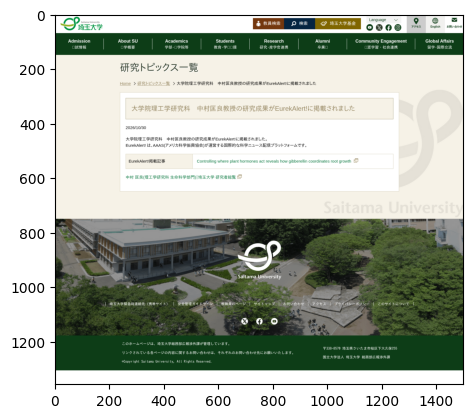

In [14]:
## 動作確認(2) 埼玉大学HPの新着情報の「研究トピックス」を1件目の記事をクリックして表示
image_file = 'dm03_selenium_screenshot_2-1.png'
# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless')
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)

# 埼玉大学HPの新着情報の「研究トピックス」をクリック
driver.set_window_size(1500,1500)
driver.get('https://www.saitama-u.ac.jp/index.html')
driver.execute_script('window.scrollBy(0, 1000);')
tab = driver.find_element(By.CSS_SELECTOR, "#tab3")
time.sleep(1) # 1秒スリープ
tab.click()
time.sleep(1) # 1秒スリープ
# 「研究トピックス」の1件目をクリック
topic = driver.find_element(By.CSS_SELECTOR, "#tab-panel3 > article:nth-child(1) > a")
topic.click()
time.sleep(1) # 1秒スリープ

# ブラウザのスクリーンショットを保存
driver.save_screenshot(image_file)
# selenium のドライバを修了
driver.quit()

# 画像を読込み変数に格納し、表示
image = plt.imread(image_file)
plt.imshow(image)

<IPython.core.display.Javascript object>

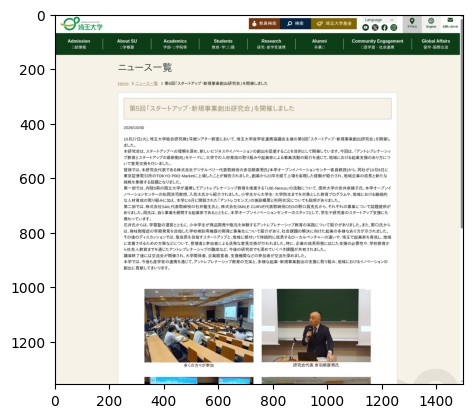

In [16]:
## 動作確認(3) 埼玉大学HPの新着情報の「全てを表示」の3件目の記事を表示
image_file = 'dm03_selenium_screenshot_2-1.png'
# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless')
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)

# 埼玉大学HPを表示
driver.set_window_size(1500,1500)
driver.get('https://www.saitama-u.ac.jp/index.html')
time.sleep(1) # 1秒スリープ
# 新着情報の「全てを表示」をクリック
# tab = driver.find_element(By.CSS_SELECTOR, "body > div.main > div.news_area > div.news_left > div > label:nth-child(2)")
# tab.click()
# time.sleep(1) # 1秒スリープ
# 3件目の記事をクリック
driver.execute_script('window.scrollBy(0, 1300);')
time.sleep(1) # 1秒スリープ
topic = driver.find_element(By.CSS_SELECTOR, "#tab-panel1 > article:nth-child(3) > a")
topic.click()
time.sleep(1) # 1秒スリープ

# ブラウザのスクリーンショットを保存
driver.save_screenshot(image_file)
# selenium のドライバを終了
driver.quit()

# 画像を読込み変数に格納し、表示
image = plt.imread(image_file)
plt.imshow(image)

In [17]:
## 動作確認(4) 埼玉大学HPの新着情報の全ての記事のURLのリストを作成・表示
image_file = 'dm03_selenium_screenshot_2-1.png'
# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless')
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)

# 埼玉大学HPの新着情報の全ての記事のURLのリストを作成
url_list = [] # リストを初期化
driver.set_window_size(1500,1500)
driver.get('https://www.saitama-u.ac.jp/index.html')
time.sleep(1) # 1秒スリープ
elements = driver.find_elements(By.CSS_SELECTOR, "#tab-panel1")
for element in elements:
    a_tags = element.find_elements(By.TAG_NAME, "a")
    for a_tag in a_tags:
        url = a_tag.get_attribute("href")
        url_list.append(url)
driver.quit()

for url in url_list:
    print(url)
print('total', len(url_list), '件')


<IPython.core.display.Javascript object>

https://www.saitama-u.ac.jp/exam_archives/202610301200.html
https://www.saitama-u.ac.jp/news_archives/202610301800.html
https://www.saitama-u.ac.jp/news_archives/202610302100.html
https://www.saitama-u.ac.jp/topics_archives/202610301700.html
https://www.saitama-u.ac.jp/news_archives/202610301600.html
https://www.saitama-u.ac.jp/topics_archives/202610301400.html
https://www.saitama-u.ac.jp/news_archives/202610281400.html
https://www.saitama-u.ac.jp/news_archives/homecoming_day_2026.html
https://www.saitama-u.ac.jp/info_archives/
total 9 件


<IPython.core.display.Javascript object>

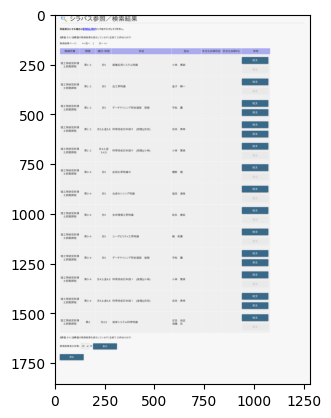

13
## 検索されたシラバスのリスト
画像応用システム特論
加工学特論
データマイニング特別演習　前期
科学技術日本語Ⅱ　(前期)(吉田)
科学技術日本語Ⅱ　(前期)(小林)
応用化学特論Ⅲ
光波センシング特論
生命情報工学特論
ユーザビリティ工学特論
データマイニング特別演習　後期
科学技術日本語Ⅰ　(後期)(小林)
科学技術日本語Ⅰ　(後期)(吉田)
地球システム科学特論
## 画像応用システム特論


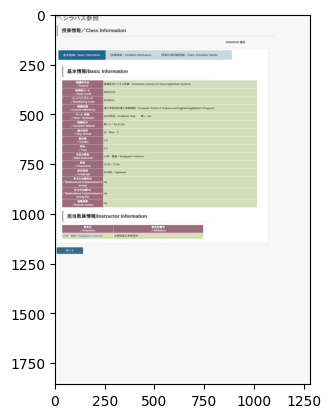

In [20]:
# 埼玉大学シラバス検索 で 条件を指定して科目を検索
image_file = 'dm03_selenium_screenshot_3.png'
image_file_2 = 'dm03_selenium_screenshot_4.png'

# selenium の初期設定
options = Options()
# Windows の場合は、次の2行のコメントアウト (ブラウザが表示される)
options.add_argument('--headless') # ブラウザを表示しない場合は、指定サイズの画像が保存可能
options.add_argument('--no-sandbox')

# URLで指定されたWebページをブラウザで表示
driver = webdriver.Chrome(options=options)
driver.set_window_size(1280,2000)
driver.get('https://syllabus.risyu.saitama-u.ac.jp/syllabus/')
time.sleep(1) # 1秒スリープ

# ドロップダウンで条件を設定
dropdown_1 = driver.find_element(By.CSS_SELECTOR, '#jikanwariShozokuCd') # 開講学部
select_1 = Select(dropdown_1)
select_1.select_by_visible_text('理工学研究科博士前期課程')
time.sleep(1) # 1秒スリープ
dropdown_2 = driver.find_element(By.CSS_SELECTOR, '#yobi') # 曜日
select_2 = Select(dropdown_2)
select_2.select_by_visible_text('月曜日')
time.sleep(1) # 1秒スリープ
dropdown_3 = driver.find_element(By.CSS_SELECTOR, '#jigen') # 時限
select_3 = Select(dropdown_3)
select_3.select_by_visible_text('5限')
time.sleep(1) # 1秒スリープ

# 「検索」をクリック
search_button = driver.find_element(By.CSS_SELECTOR, "#jikanwariKeywordForm > table > tbody > tr:nth-child(14) > td > p > input:nth-child(1)")
search_button.click()
time.sleep(1) # 1秒スリープ

# ブラウザのスクリーンショット(検索結果)を保存して表示
driver.save_screenshot(image_file)
image = plt.imread(image_file)
plt.imshow(image)
plt.show()

result_number = driver.find_element(By.CSS_SELECTOR, '#jikanwariKeywordForm > div > b:nth-child(4)').text
result_number = int(re.sub(r'件目', '', result_number))
print(result_number)

# 検索結果中のリンク=(ほぼ科目名)を表示
print('## 検索されたシラバスのリスト')
text_list = [] # リストを初期化
url_list = [] # リストを初期化
for _no in range(result_number):
    _text = driver.find_element(By.CSS_SELECTOR, f'#jikanwariKeywordForm > div > table > tbody > tr:nth-child({_no+1}) > td:nth-child(4)').text
    print(_text)
    text_list.append(_text)

# 検索結果をクリックしてシラバスのスクリーンショットを取得
print('##', text_list[0])
element = driver.find_element(By.CSS_SELECTOR, '#jikanwariKeywordForm > div > table > tbody > tr:nth-child(1) > td:nth-child(8) > input:nth-child(1)')
#jikanwariKeywordForm > div > table > tbody > tr:nth-child(1) > td:nth-child(8) > input:nth-child(1)
element.click()
time.sleep(1) # 1秒スリープ
driver.switch_to.window(driver.window_handles[1]) # 操作対象を新しいウインドウに切り替える
driver.set_window_size(1280,2000) # 新しいウインドウのサイズを変更
time.sleep(1) # 1秒スリープ

# ブラウザのスクリーンショット(検索結果)を保存して表示
driver.save_screenshot(image_file_2)
image = plt.imread(image_file_2)
plt.imshow(image)
plt.show()

# selenium のドライバを修了
driver.quit()
